# Sentinel · Dataset validation and review policy

A reproducible experiment using the same application modules as the running project. Run all cells in order. Demonstration data and fixed corpora are not evidence of production performance.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'app').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False})

## CSV schema and round trip

Exercise the exact CSV validator used by batch scoring. This synthetic labelled CSV is built in memory; no personal transactions are loaded.

In [2]:
from app.services.model import dataset,splits,train_models,metrics
from app.services.data import load_csv
from app.domain.schema import FEATURES
x,y=dataset(n=2000,seed=7)
csv=x.assign(fraud=y).to_csv(index=False)
clean,labels=load_csv(csv,labelled=True)
assert clean.shape==(2000,6) and labels.equals(y)
display(clean.head());display(clean.dtypes.to_frame('validated_dtype'))
print('CSV bytes:',len(csv.encode()),'positive labels:',int(labels.sum()))

CSV bytes: 75135 positive labels: 68


,amount,hour,distance_km,transactions_24h,account_age_days,international
0,44.77,22,62.955695,3,691,0
1,63.98,9,6.875302,7,907,0
2,32.17,15,104.353112,0,1487,1
3,15.35,18,91.520107,2,118,0
4,25.90,14,175.307679,2,79,1


,validated_dtype
amount,float64
hour,int64
distance_km,float64
transactions_24h,int64
account_age_days,int64
international,int64


## Reject broken data

Validate missing columns, negative amounts, invalid hours, missing targets and single-class targets. Clear failures are preferable to silently coercing bad training data.

In [3]:
cases={
 'missing feature':clean.drop(columns='hour').to_csv(index=False),
 'negative amount':clean.assign(amount=-1).to_csv(index=False),
 'invalid hour':clean.assign(hour=25).to_csv(index=False),
 'missing target':clean.to_csv(index=False),
 'single class':clean.assign(fraud=0).to_csv(index=False),
}
audit=[]
for case,text in cases.items():
    try:load_csv(text,labelled=True);audit.append({'case':case,'rejected':False,'message':'unexpected success'})
    except ValueError as error:audit.append({'case':case,'rejected':True,'message':str(error)})
display(pd.DataFrame(audit));assert all(row['rejected'] for row in audit)

,case,rejected,message
0,missing feature,True,"Required columns: amount, hour, distance_km, t..."
1,negative amount,True,"Required columns: amount, hour, distance_km, t..."
2,invalid hour,True,"Required columns: amount, hour, distance_km, t..."
3,missing target,True,"Required columns: amount, hour, distance_km, t..."
4,single class,True,"fraud must contain both binary classes, with n..."


## Cross-validation on development data

Reserve the test split first. Cross-validation evaluates the complete scaling/classifier pipeline on the remaining development data, avoiding scaler leakage across folds.

In [4]:
from sklearn.model_selection import StratifiedKFold,cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
xt,xv,xe,yt,yv,ye=splits(clean,labels)
development=pd.concat([xt,xv]);development_y=pd.concat([yt,yv])
assert set(development.index).isdisjoint(xe.index)
pipeline=make_pipeline(StandardScaler(),LogisticRegression(class_weight='balanced',max_iter=1000,random_state=42))
cv=cross_validate(pipeline,development,development_y,cv=StratifiedKFold(3,shuffle=True,random_state=42),scoring=['average_precision','roc_auc'],return_train_score=False)
display(pd.DataFrame(cv).round(4))
print('The holdout remains excluded from cross-validation; no hyperparameter search is performed here.')

The holdout remains excluded from cross-validation; no hyperparameter search is performed here.


,fit_time,score_time,test_average_precision,test_roc_auc
0,0.0049,0.0033,0.1200,0.7003
1,0.0040,0.0027,0.1470,0.7626
2,0.0037,0.0025,0.0712,0.7109


## Review-budget thresholds

Derive score cutoffs from validation scores at several review budgets. Apply those frozen cutoffs to the untouched test split. A fixed budget is not the same objective as maximizing F1.

,validation_review_budget,cutoff,test_review_fraction,test_precision,test_recall,test_false_positive_rate
0,0.02,0.2272,0.0075,0.0000,0.0000,0.0078
1,0.05,0.1264,0.0525,0.0952,0.1429,0.0492
2,0.10,0.0654,0.1175,0.0638,0.2143,0.1140
3,0.20,0.0397,0.2075,0.0482,0.2857,0.2047


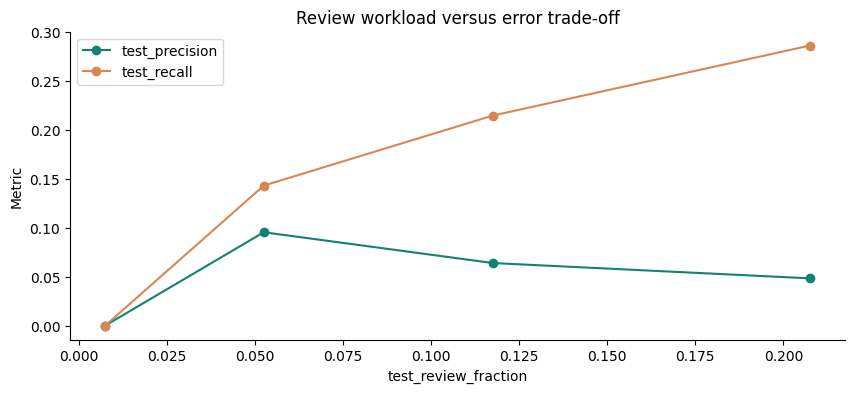

In [5]:
bundle=train_models(clean,labels);name=bundle['winner'];model=bundle['models'][name]
pv=model.predict_proba(xv)[:,1];pe=model.predict_proba(xe)[:,1]
rows=[]
for budget in [.02,.05,.10,.20]:
    cutoff=float(np.quantile(pv,1-budget));result=metrics(ye,pe,cutoff)
    rows.append({'validation_review_budget':budget,'cutoff':cutoff,
                 'test_review_fraction':float((pe>=cutoff).mean()),'test_precision':result['precision'],
                 'test_recall':result['recall'],'test_false_positive_rate':result['false_positive_rate']})
policy=pd.DataFrame(rows);display(policy.round(4))
policy.plot(x='test_review_fraction',y=['test_precision','test_recall'],marker='o',color=['#12836f','#d78753']);plt.ylabel('Metric');plt.title('Review workload versus error trade-off');plt.show()

## Serving contract for imported rows

Call the real batch-scoring endpoint. These imported records are scored by the application default synthetic model, not the separate smaller experiment trained above; the distinction is deliberate.

In [6]:
from fastapi.testclient import TestClient
from app.main import app
client=TestClient(app)
response=client.post('/api/transactions/import',json={'csv':clean.head(5).to_csv(index=False)})
assert response.status_code==200
batch=response.json();assert batch['count']==5
display(pd.DataFrame(batch['rows'])[['id','amount','probability','flagged']])
print(batch['note'])
invalid=client.post('/api/transactions/import',json={'csv':'amount,hour\n1,2'})
assert invalid.status_code==422
print('Invalid import status:',invalid.status_code)

Scored using the synthetic demonstration model; imported data is not persisted
Invalid import status: 422


,id,amount,probability,flagged
0,CSV-00005,25.90,0.112609,False
1,CSV-00002,63.98,0.031639,False
2,CSV-00003,32.17,0.026000,False
3,CSV-00004,15.35,0.008090,False
4,CSV-00001,44.77,0.003527,False


## Experiment model card

Summarize the actual fitted experiment with its data source and intended-use boundary. The dashboard and notebook share training functions; the smaller seeded experiment is not a production artifact.

In [7]:
card={'purpose':'educational transaction review','dataset':'synthetic simulator, seed 7',
      'rows':len(clean),'features':FEATURES,'prevalence':float(labels.mean()),
      'split':{'train':len(xt),'validation':len(xv),'test':len(xe)},
      'selected_model':name,'selection_metric':'validation average precision',
      'test_average_precision':bundle['metrics'][name]['average_precision'],
      'not_for':'automated financial decisions or claims of real-world fraud performance'}
display(card)
assert card['split']['train']+card['split']['validation']+card['split']['test']==len(clean)

{'purpose': 'educational transaction review',
 'dataset': 'synthetic simulator, seed 7',
 'rows': 2000,
 'features': ['amount',
  'hour',
  'distance_km',
  'transactions_24h',
  'account_age_days',
  'international'],
 'prevalence': 0.034,
 'split': {'train': 1200, 'validation': 400, 'test': 400},
 'selected_model': 'XGBoost',
 'selection_metric': 'validation average precision',
 'test_average_precision': 0.09471678199623584,
 'not_for': 'automated financial decisions or claims of real-world fraud performance'}